# PathSnap — Dataset Exploration & EDA

**Author:** P1 – Adarsh (Dataset Exploration)

This notebook covers the exploration, statistical summaries, anomaly detection, visualisations and Folium map generation for PathSnap.

**Partitions used:** `train` (80 trips) and `student_test` (10 trips). The evaluator-testing partition is **not** used.

Outputs are written to `eda/outputs/`.

## 0. Setup and paths

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
from IPython.display import display, Markdown

# Notebook lives in eda/ ; the repo root is one level up.
BASE_DIR = os.path.abspath("")
PROJECT_ROOT = os.path.dirname(BASE_DIR)

# Data location: env var PATHSNAP_DATA, otherwise the first layout that exists.
_candidates = [
    os.environ.get("PATHSNAP_DATA", ""),
    os.path.join(PROJECT_ROOT, "Student folder", "Student folder"),
    os.path.join(PROJECT_ROOT, "Student folder"),
    os.path.join(os.path.dirname(PROJECT_ROOT), "Student folder"),
]
DATA_DIR = next(p for p in _candidates if p and os.path.isdir(os.path.join(p, "train")))
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "student_test")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("DATA_DIR  :", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

DATA_DIR  : /Users/Ananya/Downloads/mlhack/Student folder
OUTPUT_DIR: /Users/Ananya/Downloads/mlhack/ml-hack-team15/eda/outputs


## 1. Helper functions

- `haversine_np`: great-circle distance in **metres**. Raw coordinates are degrees, and Euclidean distance in degrees is not physical distance.
- `load_trip_files`: reads the four headerless, whitespace-separated files of a trip:

| File | Columns | Notes |
|---|---|---|
| `.track` | lon, lat, timestamp | GPS observations, nominally 1 Hz |
| `.nodes` | lon, lat | 0-based row index = `node_id` |
| `.arcs` | from_node, to_node | 0-based row index = `arc_id` (directed road segment) |
| `.route` | arc_id | ordered reference arcs traversed |

In [2]:
def haversine_np(lon1, lat1, lon2, lat2):
    # Great-circle distance between two points on the earth, in metres.
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371008.8 * c   # mean Earth radius (m)


def load_trip_files(trip_folder):
    # Load the 4 files of a trip into DataFrames.
    trip_id = os.path.basename(trip_folder)
    track_df = pd.read_csv(os.path.join(trip_folder, f"{trip_id}.track"), sep=r"\s+", header=None,
                           names=["lon", "lat", "timestamp"])
    nodes_df = pd.read_csv(os.path.join(trip_folder, f"{trip_id}.nodes"), sep=r"\s+", header=None,
                           names=["lon", "lat"])
    nodes_df["node_id"] = np.arange(len(nodes_df))
    arcs_df = pd.read_csv(os.path.join(trip_folder, f"{trip_id}.arcs"), sep=r"\s+", header=None,
                          names=["from_node", "to_node"])
    arcs_df["arc_id"] = np.arange(len(arcs_df))
    route_file = os.path.join(trip_folder, f"{trip_id}.route")
    route_df = None
    if os.path.exists(route_file):
        route_df = pd.read_csv(route_file, sep=r"\s+", header=None, names=["arc_id"])
    return track_df, nodes_df, arcs_df, route_df

### Quick look at one trip's raw files

In [3]:
_tr, _nd, _ar, _rt = load_trip_files(os.path.join(TRAIN_DIR, "00000001"))
for name, df in [(".track", _tr), (".nodes", _nd), (".arcs", _ar), (".route", _rt)]:
    print(f"{name:7s} shape={df.shape}  dtypes={dict(df.dtypes.astype(str))}")
display(_tr.head())

.track  shape=(1315, 3)  dtypes={'lon': 'float64', 'lat': 'float64', 'timestamp': 'float64'}
.nodes  shape=(88809, 3)  dtypes={'lon': 'float64', 'lat': 'float64', 'node_id': 'int64'}
.arcs   shape=(165790, 3)  dtypes={'from_node': 'int64', 'to_node': 'int64', 'arc_id': 'int64'}
.route  shape=(525, 1)  dtypes={'arc_id': 'int64'}


,lon,lat,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


## 2. Per-trip statistics

For each trip we compute:
- **Missing values** across all four files.
- **Sampling:** share of exact 1 s steps, gaps > 2 s and > 5 s, maximum gap, timestamp monotonicity.
- **Motion:** haversine step distance, mean/max speed, and points implying speeds above 150 km/h (GPS spikes).
- **Graph integrity:** arcs that reference non-existent nodes, route ids outside the arc range.
- **Size:** node/arc/route counts, file size, bounding box.

In [4]:
def analyze_single_trip(trip_folder, partition="train"):
    # Extract statistics and detect anomalies for one trip.
    trip_id = os.path.basename(trip_folder)
    track, nodes, arcs, route = load_trip_files(trip_folder)

    # Missing values
    total_nan = (track.isnull().sum().sum() + nodes.isnull().sum().sum() + arcs.isnull().sum().sum()
                 + (route.isnull().sum().sum() if route is not None else 0))

    # Temporal & sampling analysis (monotonicity checked on the ORIGINAL order)
    raw_diffs = track["timestamp"].diff().dropna()
    is_monotonic = bool((raw_diffs > 0).all())
    time_diffs = track.sort_values("timestamp")["timestamp"].diff().dropna()
    pct_1s = (time_diffs == 1.0).mean() * 100 if len(time_diffs) > 0 else 0
    gaps_gt_2s = (time_diffs > 2.0).sum()
    gaps_gt_5s = (time_diffs > 5.0).sum()
    max_gap = time_diffs.max() if len(time_diffs) > 0 else 0
    duration_s = track["timestamp"].max() - track["timestamp"].min()

    # Spatial speed & trajectory length
    lons, lats = track["lon"].values, track["lat"].values
    dists = haversine_np(lons[:-1], lats[:-1], lons[1:], lats[1:])
    times = raw_diffs.values
    speeds_kmh = np.where(times > 0, dists / np.where(times > 0, times, 1), 0) * 3.6
    max_speed_kmh = np.max(speeds_kmh) if len(speeds_kmh) > 0 else 0
    mean_speed_kmh = np.mean(speeds_kmh) if len(speeds_kmh) > 0 else 0
    unrealistic_speed_count = (speeds_kmh > 150.0).sum()

    # Graph & route integrity
    num_nodes, num_arcs = len(nodes), len(arcs)
    invalid_arcs = ((arcs["from_node"] >= num_nodes) | (arcs["to_node"] >= num_nodes) |
                    (arcs["from_node"] < 0) | (arcs["to_node"] < 0)).sum()
    num_route = len(route) if route is not None else 0
    invalid_route = ((route["arc_id"] >= num_arcs) | (route["arc_id"] < 0)).sum() if route is not None else 0

    total_size_bytes = sum(os.path.getsize(os.path.join(trip_folder, f))
                           for f in os.listdir(trip_folder) if os.path.isfile(os.path.join(trip_folder, f)))

    return {
        "trip_id": trip_id, "partition": partition,
        "gps_points": len(track), "duration_sec": duration_s,
        "trajectory_dist_km": round(np.sum(dists) / 1000.0, 3),
        "mean_speed_kmh": round(mean_speed_kmh, 2), "max_speed_kmh": round(max_speed_kmh, 2),
        "pct_1s_sampling": round(pct_1s, 2),
        "gaps_gt_2s": int(gaps_gt_2s), "gaps_gt_5s": int(gaps_gt_5s), "max_gap_s": round(max_gap, 2),
        "is_monotonic": is_monotonic,
        "num_nodes": num_nodes, "num_arcs": num_arcs, "num_route_arcs": num_route,
        "missing_values": int(total_nan), "invalid_graph_refs": int(invalid_arcs + invalid_route),
        "unrealistic_speed_pts": int(unrealistic_speed_count),
        "file_size_kb": round(total_size_bytes / 1024, 1),
        "min_lon": track["lon"].min(), "max_lon": track["lon"].max(),
        "min_lat": track["lat"].min(), "max_lat": track["lat"].max(),
    }

In [5]:
train_trips = sorted(os.path.join(TRAIN_DIR, d) for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d)))
test_trips = sorted(os.path.join(TEST_DIR, d) for d in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, d)))
print(f"Found {len(train_trips)} Training trips and {len(test_trips)} Student-Test trips.")

all_stats, all_time_intervals = [], []
for partition, trips in [("train", train_trips), ("student_test", test_trips)]:
    for t_dir in trips:
        all_stats.append(analyze_single_trip(t_dir, partition=partition))
        tr, _, _, _ = load_trip_files(t_dir)
        all_time_intervals.extend(tr["timestamp"].diff().dropna().values)

stats_df = pd.DataFrame(all_stats)
all_time_intervals = np.array(all_time_intervals)
stats_df.to_csv(os.path.join(OUTPUT_DIR, "trips_statistics.csv"), index=False)
print("Saved per-trip statistics to outputs/trips_statistics.csv")
stats_df.head(10)

Found 80 Training trips and 10 Student-Test trips.


Saved per-trip statistics to outputs/trips_statistics.csv


,trip_id,partition,gps_points,duration_sec,trajectory_dist_km,mean_speed_kmh,max_speed_kmh,pct_1s_sampling,gaps_gt_2s,gaps_gt_5s,...,num_arcs,num_route_arcs,missing_values,invalid_graph_refs,unrealistic_speed_pts,file_size_kb,min_lon,max_lon,min_lat,max_lat
0,00000001,train,1315,1357.000,50.186,136.88,260.72,98.10,4,1,...,165790,525,0,0,648,3593.7,8.570524,8.647860,49.844053,50.211882
1,00000002,train,7243,8933.156,55.872,27.29,134.19,97.45,124,78,...,16139,262,0,0,0,541.7,10.999961,11.050902,47.658344,47.695459
2,00000003,train,821,823.000,8.420,36.85,104.87,99.63,0,0,...,18028,79,0,0,0,376.0,37.154202,37.201595,55.977135,56.007585
3,00000004,train,1064,5217.000,27.891,25.84,104.98,53.81,432,320,...,15499,320,0,0,0,325.5,12.342280,12.459615,52.590308,52.718960
4,00000005,train,1045,1044.000,31.326,108.02,229.47,100.00,0,0,...,1579,105,0,0,52,62.6,35.485577,35.544315,49.357581,49.613085
5,00000006,train,1450,2102.000,19.391,48.02,168.10,99.17,10,9,...,6757,261,0,0,1,172.7,37.276002,37.317675,55.429164,55.487229
6,00000008,train,3093,3093.000,25.044,29.15,252.63,99.97,0,0,...,10421,173,0,0,1,301.7,-86.584860,-86.567487,34.733275,34.753704
7,00000010,train,2711,2710.000,25.815,34.29,141.30,100.00,0,0,...,15715,210,0,0,0,403.0,37.357893,37.394790,55.786261,55.832857
8,00000011,train,2828,3735.000,54.972,69.99,181.16,99.96,1,1,...,5393,565,0,0,8,192.2,59.647057,60.016866,56.041788,56.067535
9,00000012,train,1608,1608.000,41.580,93.12,198.76,99.94,0,0,...,38599,205,0,0,46,772.5,44.044515,44.389906,36.175914,36.263587


## 3. Dataset inventory (per partition)

In [6]:
inv = stats_df.groupby("partition").agg(
    num_trips=("trip_id", "count"),
    total_gps_points=("gps_points", "sum"),
    avg_gps_points=("gps_points", "mean"),
    min_gps_points=("gps_points", "min"),
    max_gps_points=("gps_points", "max"),
    avg_duration_sec=("duration_sec", "mean"),
    avg_nodes=("num_nodes", "mean"),
    avg_arcs=("num_arcs", "mean"),
    total_missing_values=("missing_values", "sum"),
    total_invalid_refs=("invalid_graph_refs", "sum"),
).round(2).reset_index()
inv.to_csv(os.path.join(OUTPUT_DIR, "dataset_inventory.csv"), index=False)
inv

,partition,num_trips,total_gps_points,avg_gps_points,min_gps_points,max_gps_points,avg_duration_sec,avg_nodes,avg_arcs,total_missing_values,total_invalid_refs
0,student_test,10,19160,1916.00,262,3958,2025.0,9068.90,18504.1,0,0
1,train,80,208417,2605.21,361,19313,5680.4,24168.56,48461.3,0,0


### Missing values and integrity checks

In [7]:
checks = pd.DataFrame({
    "missing_values": stats_df.groupby("partition")["missing_values"].sum(),
    "invalid_graph_refs": stats_df.groupby("partition")["invalid_graph_refs"].sum(),
    "non_monotonic_trips": (~stats_df["is_monotonic"]).groupby(stats_df["partition"]).sum(),
    "trips_with_gap_gt_5s": (stats_df["gaps_gt_5s"] > 0).groupby(stats_df["partition"]).sum(),
    "trips_with_speed_spikes": (stats_df["unrealistic_speed_pts"] > 0).groupby(stats_df["partition"]).sum(),
})
checks

,missing_values,invalid_graph_refs,non_monotonic_trips,trips_with_gap_gt_5s,trips_with_speed_spikes
partition,,,,,
student_test,0,0,0,2,8
train,0,0,0,45,52


## 4. Anomaly register
A trip is flagged if it has a GPS dropout longer than 5 s, a step implying a speed above 150 km/h, or non-monotonic timestamps.

In [8]:
anomalies = stats_df[(stats_df["gaps_gt_5s"] > 0) | (stats_df["unrealistic_speed_pts"] > 0) | (~stats_df["is_monotonic"])].copy()
anomalies.to_csv(os.path.join(OUTPUT_DIR, "anomalies_detected.csv"), index=False)
print(f"Identified {len(anomalies)} trips with anomalies (dropouts >5s, GPS speed spikes or non-monotonic time).")
anomalies[["trip_id", "partition", "gps_points", "gaps_gt_5s", "max_gap_s", "unrealistic_speed_pts", "max_speed_kmh", "is_monotonic"]] \
    .sort_values("max_gap_s", ascending=False).head(15)

Identified 75 trips with anomalies (dropouts >5s, GPS speed spikes or non-monotonic time).


,trip_id,partition,gps_points,gaps_gt_5s,max_gap_s,unrealistic_speed_pts,max_speed_kmh,is_monotonic
72,00000090,train,536,20,153064.0,0,121.58,True
61,00000078,train,2909,124,52810.0,5,182.99,True
55,00000069,train,2067,2,2658.0,1,150.62,True
16,00000021,train,15783,2,2161.0,4,165.42,True
8,00000011,train,2828,1,909.0,8,181.16,True
34,00000042,train,7739,45,670.0,3,210.22,True
64,00000081,train,3224,129,536.0,0,145.29,True
18,00000024,train,801,4,458.0,171,236.66,True
36,00000044,train,546,2,341.0,0,130.34,True
67,00000084,train,16031,4,312.0,4,177.21,True


## 5. Visualisations
### 5.1 GPS points and reference-route length per trip (train + student_test)

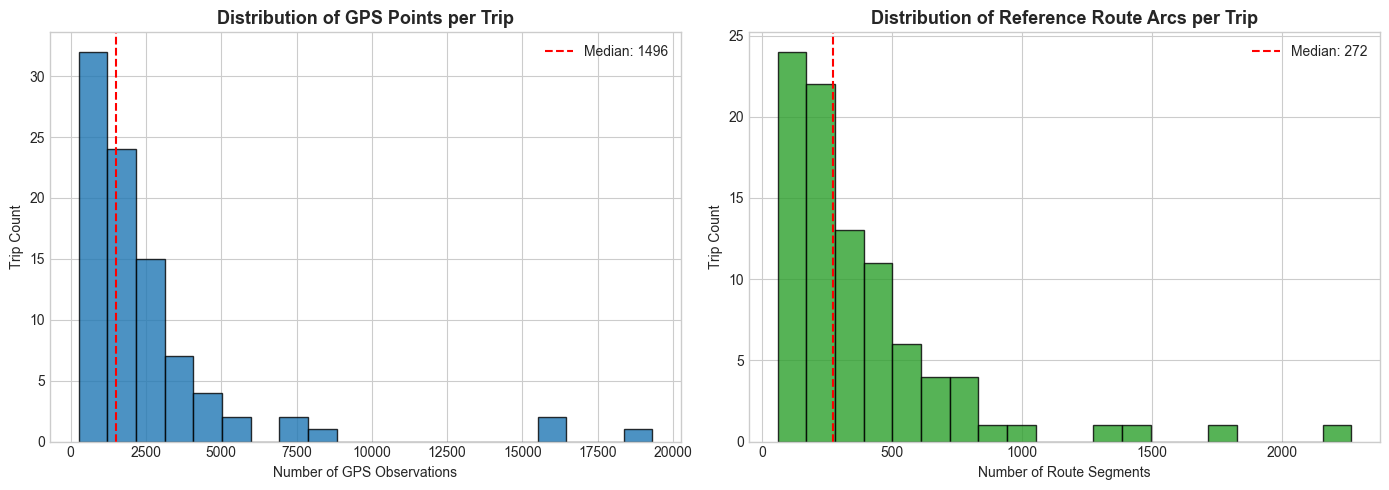

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(stats_df["gps_points"], bins=20, color="#1f77b4", edgecolor="black", alpha=0.8)
ax[0].set_title("Distribution of GPS Points per Trip", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Number of GPS Observations"); ax[0].set_ylabel("Trip Count")
ax[0].axvline(stats_df["gps_points"].median(), color="red", linestyle="--", label=f"Median: {stats_df['gps_points'].median():.0f}")
ax[0].legend()

ax[1].hist(stats_df["num_route_arcs"], bins=20, color="#2ca02c", edgecolor="black", alpha=0.8)
ax[1].set_title("Distribution of Reference Route Arcs per Trip", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Number of Route Segments"); ax[1].set_ylabel("Trip Count")
ax[1].axvline(stats_df["num_route_arcs"].median(), color="red", linestyle="--", label=f"Median: {stats_df['num_route_arcs'].median():.0f}")
ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "gps_points_distribution.png"), dpi=200)
plt.show()

### 5.2 Sampling interval distribution (train + student_test)

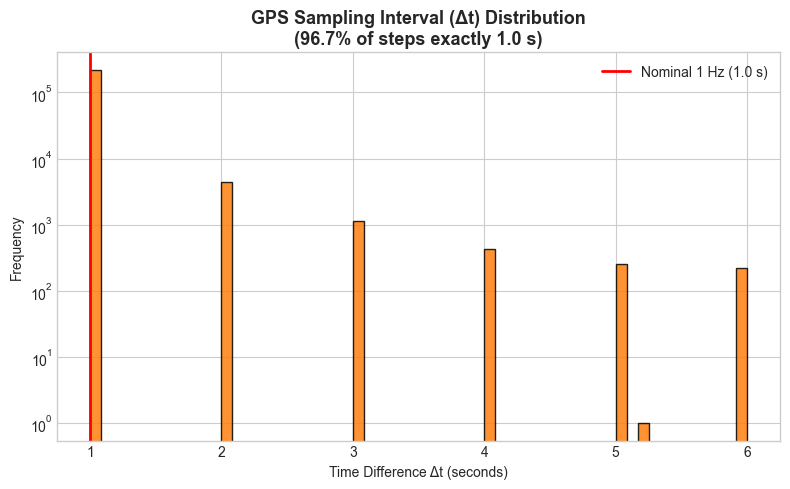

Steps > 6 s (not shown): 1039 | max Δt = 153064.0 s


In [10]:
pct_exact_1s = (all_time_intervals == 1.0).mean() * 100
fig, ax = plt.subplots(figsize=(8, 5))
filtered = all_time_intervals[(all_time_intervals >= 0) & (all_time_intervals <= 6)]
ax.hist(filtered, bins=60, color="#ff7f0e", edgecolor="black", alpha=0.85)
ax.set_title(f"GPS Sampling Interval (Δt) Distribution\n({pct_exact_1s:.1f}% of steps exactly 1.0 s)", fontsize=13, fontweight="bold")
ax.set_xlabel("Time Difference Δt (seconds)"); ax.set_ylabel("Frequency"); ax.set_yscale("log")
ax.axvline(1.0, color="red", linewidth=2, label="Nominal 1 Hz (1.0 s)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sampling_interval_distribution.png"), dpi=200)
plt.show()
print(f"Steps > 6 s (not shown): {(all_time_intervals > 6).sum()} | max Δt = {all_time_intervals.max():.1f} s")

### 5.3 Road-network scale per trip

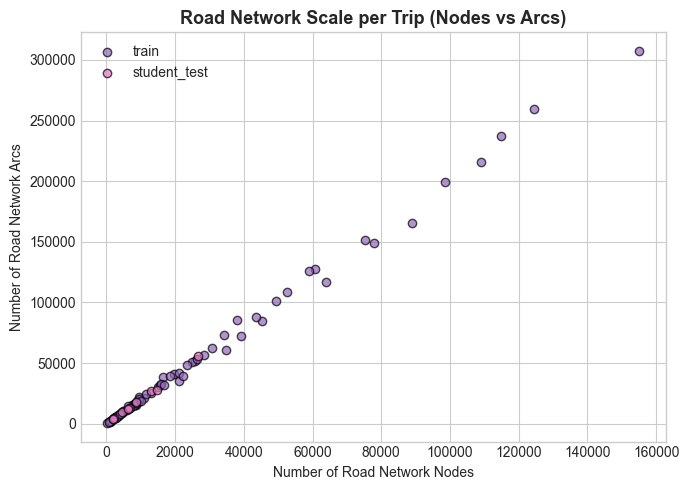

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
for part, c in [("train", "#9467bd"), ("student_test", "#e377c2")]:
    s = stats_df[stats_df["partition"] == part]
    ax.scatter(s["num_nodes"], s["num_arcs"], c=c, alpha=0.7, edgecolors="black", label=part)
ax.set_title("Road Network Scale per Trip (Nodes vs Arcs)", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Road Network Nodes"); ax.set_ylabel("Number of Road Network Arcs"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "road_network_complexity.png"), dpi=200)
plt.show()

### 5.4 Spatial trajectory plot: sample trip `00000001` (train)

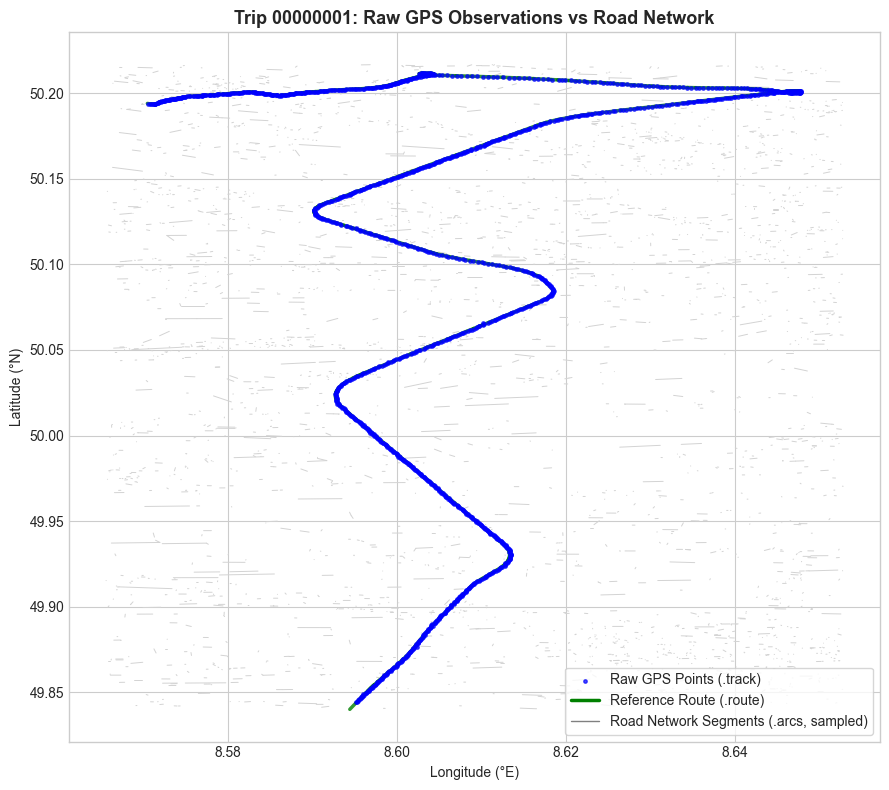

In [12]:
SAMPLE_TRIP = "00000001"
tr, nd, ar, rt = load_trip_files(os.path.join(TRAIN_DIR, SAMPLE_TRIP))

# Sub-graph inside the trajectory bounding box (+0.005° margin)
min_lon, max_lon = tr["lon"].min() - 0.005, tr["lon"].max() + 0.005
min_lat, max_lat = tr["lat"].min() - 0.005, tr["lat"].max() + 0.005
node_set = set(nd[(nd["lon"] >= min_lon) & (nd["lon"] <= max_lon) &
                  (nd["lat"] >= min_lat) & (nd["lat"] <= max_lat)]["node_id"].values)
sub_arcs = ar[ar["from_node"].isin(node_set) & ar["to_node"].isin(node_set)]
node_coords = dict(zip(nd["node_id"], zip(nd["lon"], nd["lat"])))

fig, ax = plt.subplots(figsize=(9, 8))
for _, arc_row in sub_arcs.sample(min(3000, len(sub_arcs)), random_state=42).iterrows():
    c1, c2 = node_coords[arc_row["from_node"]], node_coords[arc_row["to_node"]]
    ax.plot([c1[0], c2[0]], [c1[1], c2[1]], color="lightgray", linewidth=0.7, zorder=1)

for arc_idx in rt["arc_id"].values:
    if arc_idx < len(ar):
        n1, n2 = ar.iloc[arc_idx][["from_node", "to_node"]]
        c1, c2 = node_coords[n1], node_coords[n2]
        ax.plot([c1[0], c2[0]], [c1[1], c2[1]], color="green", linewidth=2.5, alpha=0.8, zorder=3)

ax.scatter(tr["lon"], tr["lat"], color="blue", s=6, label="Raw GPS Points (.track)", alpha=0.7, zorder=4)
ax.plot([], [], color="green", linewidth=2.5, label="Reference Route (.route)")
ax.plot([], [], color="gray", linewidth=1, label="Road Network Segments (.arcs, sampled)")
ax.set_title(f"Trip {SAMPLE_TRIP}: Raw GPS Observations vs Road Network", fontsize=13, fontweight="bold")
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)"); ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "trajectory_spatial_plot.png"), dpi=200)
plt.show()

## 6. Interactive Folium map: trip `00000001` (train)
Layers: road network (sampled), reference route, and the noisy GPS track. Use the layer control in the top-right to toggle them.

In [13]:
m = folium.Map(location=[tr["lat"].mean(), tr["lon"].mean()], zoom_start=15, tiles="OpenStreetMap")

road_layer = folium.FeatureGroup(name="Road Network (.arcs)", show=True)
for _, arc_row in sub_arcs.sample(min(1200, len(sub_arcs)), random_state=42).iterrows():
    c1, c2 = node_coords[arc_row["from_node"]], node_coords[arc_row["to_node"]]
    folium.PolyLine([[c1[1], c1[0]], [c2[1], c2[0]]], color="gray", weight=1.5, opacity=0.5).add_to(road_layer)
road_layer.add_to(m)

gt_layer = folium.FeatureGroup(name="Reference Route (.route)", show=True)
for arc_idx in rt["arc_id"].values:
    if arc_idx < len(ar):
        n1, n2 = ar.iloc[arc_idx][["from_node", "to_node"]]
        c1, c2 = node_coords[n1], node_coords[n2]
        folium.PolyLine([[c1[1], c1[0]], [c2[1], c2[0]]], color="#28a745", weight=4, opacity=0.85,
                        tooltip=f"Reference Arc ID: {arc_idx}").add_to(gt_layer)
gt_layer.add_to(m)

gps_layer = folium.FeatureGroup(name="Noisy GPS Observations (.track)", show=True)
folium.PolyLine(tr[["lat", "lon"]].values.tolist(), color="#007bff", weight=2, opacity=0.6, dash_array="5, 5").add_to(gps_layer)
for idx, row in tr.iloc[::3].iterrows():
    folium.CircleMarker(location=[row["lat"], row["lon"]], radius=3, color="#0056b3", fill=True,
                        fill_color="#007bff", fill_opacity=0.8,
                        popup=f"GPS Point {idx}<br>Time: {row['timestamp']:.1f}s<br>Lat: {row['lat']:.5f}<br>Lon: {row['lon']:.5f}"
                        ).add_to(gps_layer)
gps_layer.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.save(os.path.join(OUTPUT_DIR, "interactive_trip_folium.html"))
print("Saved outputs/interactive_trip_folium.html")
m

Saved outputs/interactive_trip_folium.html
